# Drift Detection and Model Monitoring

**What you'll learn**

- The precise taxonomy of "model rot": covariate drift ($P(X)$ moves), concept drift
  ($P(Y\mid X)$ moves), and label shift ($P(Y)$ moves) — and why the distinction dictates
  what your monitoring can and cannot see.
- PSI implemented from scratch: the binning, the formula, where the 0.1 / 0.25 rules of
  thumb come from — and a null simulation showing exactly how arbitrary those thresholds
  are (the expected PSI of *identical* distributions depends on sample size and bin count).
- A 30-month simulated production stream for a credit-scoring model with four staged
  regimes: stable, benign covariate drift, a data-quality bug on a key feature, and a
  recession (concept drift). You will watch each detector fire — or stay silent — in each.
- The two cases every senior must be able to show: **features drift hard but AUC holds**,
  and **a modest drift on one key feature kills AUC**. Drift alarms are not model
  failure; alerts must be tied to expected impact.
- The delayed-label problem: labels mature in ~90 days, so today's performance is
  unmeasurable today. What to monitor in the blind window, and the immature-label bias
  that flatters early reads.
- A backtest of retraining policies on the stream — never vs monthly vs triggered — with
  the label delay honestly enforced, showing why "retrain on breach" is weaker than it
  sounds and why a data bug needs a pipeline fix, not a retrain.

**Why it matters in interviews**

- "Your model has been in production for a year — how do you know it's still good?" is a
  staple senior ML system-design screen. The expected answer is a layered monitoring
  design, not "we track AUC."
- "Labels arrive after 90 days — what do you monitor?" tests whether you understand the
  difference between detection (label-free, immediate) and evaluation (delayed, definitive).
- PSI mechanics-and-limits is a classic depth probe in credit, fraud, and ads: anyone can
  recite 0.1/0.25; seniors know those numbers have no statistical basis and how to
  calibrate real thresholds.
- Retraining-policy questions ("scheduled or triggered? what triggers?") separate people
  who have operated models from people who have only trained them.

Prerequisites: the credit-model setting mirrors
[../09_finance_and_operations/01_credit_scorecard.ipynb](../09_finance_and_operations/01_credit_scorecard.ipynb);
calibration and proper scoring live in
[../04_ml_tabular/03_evaluation_calibration.ipynb](../04_ml_tabular/03_evaluation_calibration.ipynb);
the "everything is significant at large n" theme echoes
[../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import expit, logit
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.5, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

## 1. Why models rot: three different ways the world moves

A supervised model is a frozen estimate of $P(Y \mid X)$ fitted on a snapshot of
$P(X, Y)$. Production decay is always some factorization of $P(X,Y) = P(Y\mid X)\,P(X)
= P(X\mid Y)\,P(Y)$ moving:

| Name | What moves | What stays | Canonical cause | Visible without labels? |
|---|---|---|---|---|
| **Covariate drift** (data drift) | $P(X)$ | $P(Y\mid X)$ | new marketing channel, seasonality, pipeline change | **Yes** — compare feature distributions |
| **Concept drift** | $P(Y\mid X)$ | often $P(X)$ | recession, competitor move, fraudster adaptation, policy change | **No** — same inputs, different outcomes |
| **Label shift** (prior shift) | $P(Y)$ | $P(X\mid Y)$ | fraud wave, epidemic phase, macro cycle | Indirectly — via the $P(X)$ mixture and, later, the observed base rate |

Three consequences a senior should state unprompted:

1. **Covariate drift is detectable but not necessarily harmful.** If $P(Y\mid X)$ is
   unchanged and the model generalizes to the new region of $X$, big drift can cost zero
   performance. Alarm volume ≠ risk.
2. **Concept drift is harmful but not necessarily detectable** from inputs. If $P(X)$
   doesn't move, every feature-drift and score-drift monitor stays green while the model
   silently mis-ranks and mis-calibrates. Only outcome contact (labels, even delayed or
   sampled) reveals it.
3. **Data-quality bugs masquerade as drift.** In practice the most common "drift" alarm
   is an upstream schema/ETL change. The fix is engineering, not retraining — retraining
   on a bug *bakes it in*.

**Setting.** We build a credit-default model (features and magnitudes as in a consumer
lending book), deploy it, and stream 30 months of applications through four regimes.
Because we simulate, we know the true default probability of every applicant — so we can
score every monitoring signal against ground truth, which is exactly what you can never
do in production and why this rehearsal is worth doing.

In [2]:
FEATURES = ["income", "debt_to_income", "utilization", "delinq_24m",
            "credit_history_years", "inquiries_6m", "months_at_address"]
LABEL_DELAY = 3          # months until a cohort's default labels are mature
N_MONTH = 3_000          # applications per production month
N_MONTHS = 30


def gen_applications(n, rng, *, months_at_address_mean=60.0, income_mult=1.00,
                     util_zero_frac=0.0, macro="normal"):
    """One batch of loan applications.

    - `months_at_address_mean`, `income_mult`: change P(X) (covariate drift).
    - `util_zero_frac`: an upstream bug that coerces missing utilization to 0.0 for a
      random fraction of records — the *observed* feature is corrupted, true risk isn't.
    - `macro="recession"`: changes P(Y|X) itself (concept drift): the same applicant is
      riskier, delinquencies and leverage bite harder, income protects less.
    """
    income = rng.lognormal(np.log(55.0), 0.5, n) * income_mult      # $k / year
    dti = rng.beta(2.0, 5.0, n) * 0.9                               # debt-to-income
    util = rng.beta(1.4, 2.6, n)                                    # revolving utilization
    delinq = rng.poisson(0.35, n)                                   # delinquencies, 24m
    ch_years = rng.gamma(4.0, 3.0, n)                               # credit history length
    inq = rng.poisson(1.0, n)                                       # hard inquiries, 6m
    addr = rng.gamma(2.0, months_at_address_mean / 2.0, n)          # months at address

    if macro == "normal":
        z = (-2.30 + 3.6 * (util - 0.35) + 2.6 * (dti - 0.257)
             + 0.70 * (delinq - 0.35) + 0.18 * (inq - 1.0)
             - 0.06 * (ch_years - 12.0) - 1.10 * (np.log(income) - np.log(55.0)))
    else:  # recession: P(Y | X) changes — same X, different risk surface
        z = (-1.55 + 2.2 * (util - 0.35) + 3.4 * (dti - 0.257)
             + 1.50 * (delinq - 0.35) + 0.35 * (inq - 1.0)
             - 0.06 * (ch_years - 12.0) - 0.25 * (np.log(income) - np.log(55.0)))
    p_true = expit(z)
    default = (rng.random(n) < p_true).astype(int)

    util_obs = util.copy()
    if util_zero_frac > 0:                       # the pipeline bug: null -> 0.0
        util_obs[rng.random(n) < util_zero_frac] = 0.0

    return pd.DataFrame({
        "income": income, "debt_to_income": dti, "utilization": util_obs,
        "utilization_true": util,                # kept for pedagogy; never a model input
        "delinq_24m": delinq, "credit_history_years": ch_years,
        "inquiries_6m": inq, "months_at_address": addr,
        "default": default, "p_true": p_true,
    })


train_df = gen_applications(40_000, rng)
test_df = gen_applications(10_000, rng)          # held-out, same vintage as training

model_0 = HistGradientBoostingClassifier(max_iter=150, random_state=42)
model_0.fit(train_df[FEATURES], train_df["default"])

ref_scores_0 = model_0.predict_proba(test_df[FEATURES])[:, 1]
auc_test0 = roc_auc_score(test_df["default"], ref_scores_0)
auc_bayes = roc_auc_score(test_df["default"], test_df["p_true"])

print(f"training base default rate : {train_df['default'].mean():.3f}")
print(f"deploy-time test AUC       : {auc_test0:.3f}")
print(f"Bayes-optimal AUC (oracle) : {auc_bayes:.3f}   <- irreducible ceiling")

perm = permutation_importance(model_0, test_df[FEATURES], test_df["default"],
                              scoring="roc_auc", n_repeats=5, random_state=42)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
print("\npermutation importance (AUC drop when feature is scrambled):")
print(importance.round(4))

training base default rate : 0.132
deploy-time test AUC       : 0.781
Bayes-optimal AUC (oracle) : 0.788   <- irreducible ceiling



permutation importance (AUC drop when feature is scrambled):
utilization             0.1307
income                  0.0560
delinq_24m              0.0291
debt_to_income          0.0232
credit_history_years    0.0181
inquiries_6m            0.0035
months_at_address      -0.0009
dtype: float64


The model is close to the Bayes ceiling, `utilization` and `income` carry most of the
signal, and `months_at_address` carries essentially none (its true coefficient is zero).
Remember that importance profile — it decides which drifts hurt.

### The production stream: four staged regimes

| Months | Regime | What actually changes | Taxonomy |
|---|---|---|---|
| 1–6 | **Stable** | nothing | — |
| 7–12 | **Marketing campaign** | applicant mix: much shorter `months_at_address` (mean 60 → 18), incomes ~10% higher | covariate drift, *benign* |
| 13–18 | **Pipeline bug** | upstream release coerces missing `utilization` to 0.0 for ~20% of records | covariate/data-quality drift, *harmful* |
| 19–30 | **Recession** | bug fixed; $P(Y\mid X)$ shifts — delinquencies and leverage weigh more, income protects less; base rate jumps ~70% | concept drift ⇒ label shift |

In [3]:
def month_params(m):
    if m <= 6:
        return {}
    if m <= 12:
        return dict(months_at_address_mean=18.0, income_mult=1.10)
    if m <= 18:
        return dict(util_zero_frac=0.20)
    return dict(macro="recession")


REGIMES = [
    (1, 6, "01-06 stable", "tab:green"),
    (7, 12, "07-12 benign drift", "tab:blue"),
    (13, 18, "13-18 data bug", "tab:red"),
    (19, 30, "19-30 recession", "tab:purple"),
]


def regime_label(m):
    for lo, hi, name, _ in REGIMES:
        if lo <= m <= hi:
            return name


def shade_regimes(ax):
    for lo, hi, name, color in REGIMES:
        ax.axvspan(lo - 0.5, hi + 0.5, alpha=0.08, color=color)


stream = pd.concat(
    [gen_applications(N_MONTH, rng, **month_params(m)).assign(month=m)
     for m in range(1, N_MONTHS + 1)],
    ignore_index=True,
)

print(stream.groupby(stream["month"].map(regime_label))
      .agg(n=("default", "size"), true_bad_rate=("default", "mean"),
           mean_util_observed=("utilization", "mean"),
           mean_months_at_address=("months_at_address", "mean")).round(3))

                        n  true_bad_rate  mean_util_observed  mean_months_at_address
month                                                                               
01-06 stable        18000          0.133               0.349                  59.673
07-12 benign drift  18000          0.123               0.348                  18.057
13-18 data bug      18000          0.137               0.279                  59.910
19-30 recession     36000          0.225               0.351                  59.875


## 2. Detection: PSI from scratch

The **Population Stability Index** compares a binned reference distribution (usually
deciles of the training/validation data) against production:

$$\mathrm{PSI} = \sum_{i=1}^{B} (a_i - e_i)\,\ln\frac{a_i}{e_i}$$

where $e_i$ is the reference share in bin $i$ and $a_i$ the production share. It is the
*symmetrized* KL divergence (Jeffreys divergence) between the two binned distributions —
hence always ≥ 0, and 0 iff the binned shares match exactly.

Implementation decisions that actually matter:
- **Bin on the reference quantiles**, not equal-width — equal-width bins on skewed
  features put nearly all mass in one bin and go blind (Exercise 1).
- **Freeze the bin edges at deploy time.** The reference is the world the model was
  validated in; re-deriving edges monthly quietly redefines the question.
- **Handle empty bins** (an $\epsilon$ floor) and **collapse duplicate quantile edges**
  for discrete features like `delinq_24m`.

In [4]:
def psi(reference, actual, n_bins=10, eps=1e-4):
    """PSI with quantile bins defined on `reference`. Handles ties/discrete features."""
    reference = np.asarray(reference)
    actual = np.asarray(actual)
    # interior quantile edges; np.unique collapses duplicates on discrete features
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, n_bins + 1)[1:-1]))
    ref_frac = np.bincount(np.searchsorted(edges, reference, side="right"),
                           minlength=len(edges) + 1) / len(reference)
    act_frac = np.bincount(np.searchsorted(edges, actual, side="right"),
                           minlength=len(edges) + 1) / len(actual)
    ref_frac = np.clip(ref_frac, eps, None)
    act_frac = np.clip(act_frac, eps, None)
    return float(np.sum((act_frac - ref_frac) * np.log(act_frac / ref_frac)))


demo = pd.Series({
    "months_at_address, month 3 (stable)":
        psi(train_df["months_at_address"], stream.loc[stream["month"] == 3, "months_at_address"]),
    "months_at_address, month 10 (campaign)":
        psi(train_df["months_at_address"], stream.loc[stream["month"] == 10, "months_at_address"]),
    "utilization, month 15 (bug)":
        psi(train_df["utilization"], stream.loc[stream["month"] == 15, "utilization"]),
})
print(demo.round(4))

months_at_address, month 3 (stable)       0.0039
months_at_address, month 10 (campaign)    2.7245
utilization, month 15 (bug)               0.2501
dtype: float64


### The 0.1 / 0.25 rules of thumb — and why they are folklore

Industry convention (inherited from 1990s credit-scorecard practice, not from any
derivation): PSI < 0.1 "stable", 0.1–0.25 "moderate shift, investigate", > 0.25
"major shift, action required".

The problem: **PSI is a statistic with a sampling distribution, and the thresholds ignore
it.** Under *no drift at all*, a chi-square approximation gives
$\mathbb{E}[\mathrm{PSI}] \approx (B-1)\left(\tfrac{1}{n_{ref}} + \tfrac{1}{n_{prod}}\right)$
— it scales with bin count and inversely with sample size. So a fixed 0.1 threshold is
simultaneously too twitchy for small segments and numb for huge ones. Watch:

PSI between two samples of the SAME distribution (no drift):
              mean null PSI (sim)  95th pct (sim)  (B-1)(1/n+1/m) approx
n per sample                                                            
200                        0.0911          0.1795                 0.0900
1000                       0.0182          0.0332                 0.0180
5000                       0.0037          0.0067                 0.0036
50000                      0.0004          0.0007                 0.0004


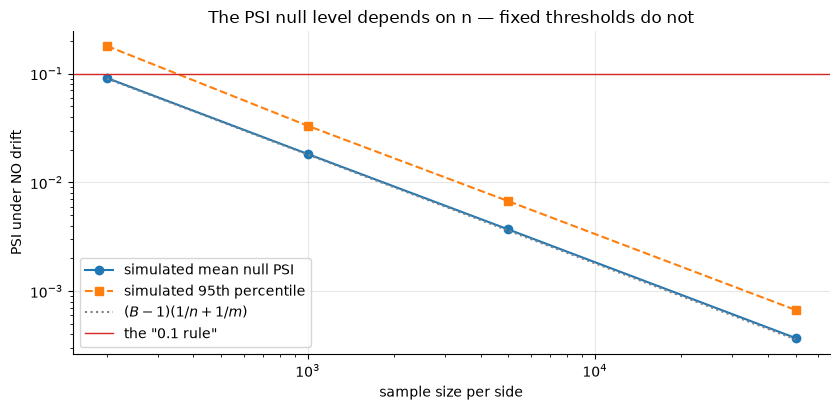

In [5]:
B = 10
sizes = [200, 1_000, 5_000, 50_000]
null_sims = {n: np.array([psi(rng.normal(size=n), rng.normal(size=n), n_bins=B)
                          for _ in range(300)])
             for n in sizes}

null_table = pd.DataFrame({
    "mean null PSI (sim)": {n: s.mean() for n, s in null_sims.items()},
    "95th pct (sim)": {n: np.quantile(s, 0.95) for n, s in null_sims.items()},
    "(B-1)(1/n+1/m) approx": {n: (B - 1) * (2 / n) for n in sizes},
})
null_table.index.name = "n per sample"
print("PSI between two samples of the SAME distribution (no drift):")
print(null_table.round(4))

fig, ax = plt.subplots()
ax.loglog(sizes, [null_sims[n].mean() for n in sizes], "o-", label="simulated mean null PSI")
ax.loglog(sizes, [np.quantile(null_sims[n], 0.95) for n in sizes], "s--",
          label="simulated 95th percentile")
ax.loglog(sizes, [(B - 1) * 2 / n for n in sizes], ":", color="gray",
          label=r"$(B-1)(1/n+1/m)$")
ax.axhline(0.1, color="tab:red", lw=1, label='the "0.1 rule"')
ax.set_xlabel("sample size per side")
ax.set_ylabel("PSI under NO drift")
ax.set_title("The PSI null level depends on n — fixed thresholds do not")
ax.legend()
plt.show()

With ~200 records per side (a small segment, a slow day) the *no-drift* 95th percentile
flirts with 0.1: the "investigate" rule fires on pure noise. With 50k per side the null
level is ~0.0004, so PSI = 0.05 — officially "stable" — is an enormous, real shift.
The senior fix: **calibrate thresholds against your own null** (bootstrap resample the
reference against itself at production sample sizes) rather than quoting folklore, and
keep per-segment sample sizes in mind. We will need exactly this in a moment: score
distributions are far tighter than raw features, and folklore thresholds never fire on
them.

### Per-feature KS tests — and the large-n trap

The two-sample Kolmogorov–Smirnov test is the usual "statistical" alternative: no
binning, an actual p-value. But at production scale the p-value answers the wrong
question — with enough data *any* nonzero drift is detectable, so everything is
"significant". Monitor the **effect size** (the KS statistic = max CDF gap), not the
p-value.

In [6]:
def ks_table(month):
    cur = stream[stream["month"] == month]
    rows = {f: stats.ks_2samp(train_df[f], cur[f]) for f in FEATURES}
    return pd.DataFrame({f: {"KS stat": r.statistic, "p": r.pvalue}
                         for f, r in rows.items()}).T


print("month 3 (stable):")
print(ks_table(3).round(4))
print("\nmonth 10 (campaign):")
print(ks_table(10).round(4))

# a practically irrelevant drift, huge n: income up 1%
big_ref = rng.lognormal(np.log(55.0), 0.5, 300_000)
big_prod = rng.lognormal(np.log(55.0 * 1.01), 0.5, 300_000)
ks = stats.ks_2samp(big_ref, big_prod)
print(f"\n1% income shift at n=300k/side: KS p = {ks.pvalue:.1e}  (certain drift!)"
      f"   KS stat = {ks.statistic:.4f}, PSI = {psi(big_ref, big_prod):.4f}  (who cares)")

month 3 (stable):
                      KS stat       p
income                 0.0187  0.2821
debt_to_income         0.0148  0.5731
utilization            0.0237  0.0862
delinq_24m             0.0063  0.9999
credit_history_years   0.0142  0.6238
inquiries_6m           0.0066  0.9997
months_at_address      0.0157  0.4887

month 10 (campaign):
                      KS stat       p
income                 0.0989  0.0000
debt_to_income         0.0165  0.4284
utilization            0.0210  0.1661
delinq_24m             0.0133  0.6979
credit_history_years   0.0128  0.7482
inquiries_6m           0.0091  0.9745
months_at_address      0.5814  0.0000



1% income shift at n=300k/side: KS p = 4.4e-10  (certain drift!)   KS stat = 0.0086, PSI = 0.0003  (who cares)


### Monitor the score distribution — drift through the model's eyes

Per-feature monitors are univariate and impact-blind. The **score distribution** is the
model's own one-dimensional summary of the input distribution: drift in any feature
*that the model actually uses* shows up in the scores, weighted exactly by how much the
model uses it. Score PSI is the single highest-value drift metric you can run.

- Feature drifts, scores don't move ⇒ the model doesn't care (benign, by construction).
- Scores move ⇒ decisions move (approval rates, queue volumes) *even if the model is
  still accurate* — you need to know regardless.
- **Folklore thresholds do not transfer.** Score distributions are much tighter than raw
  features, so score PSI lives on a smaller scale; waiting for 0.25 means never alerting.
  Calibrate: the no-drift level here is $(B-1)(1/n_{ref}+1/n_{prod}) \approx 0.004$, so
  we set the alert at ~5x null, `SCORE_ALERT = 0.02`.
- Limitation (crucial): scores are a function of $X$ only. If $P(X)$ is stable and
  $P(Y\mid X)$ moves — concept drift — **score monitoring stays green while the model
  fails.** We will watch exactly that happen in the recession regime.

One subtlety: use *held-out* scores as the reference, not training-set scores —
in-sample scores are over-separated and would register fake "drift" on day one.

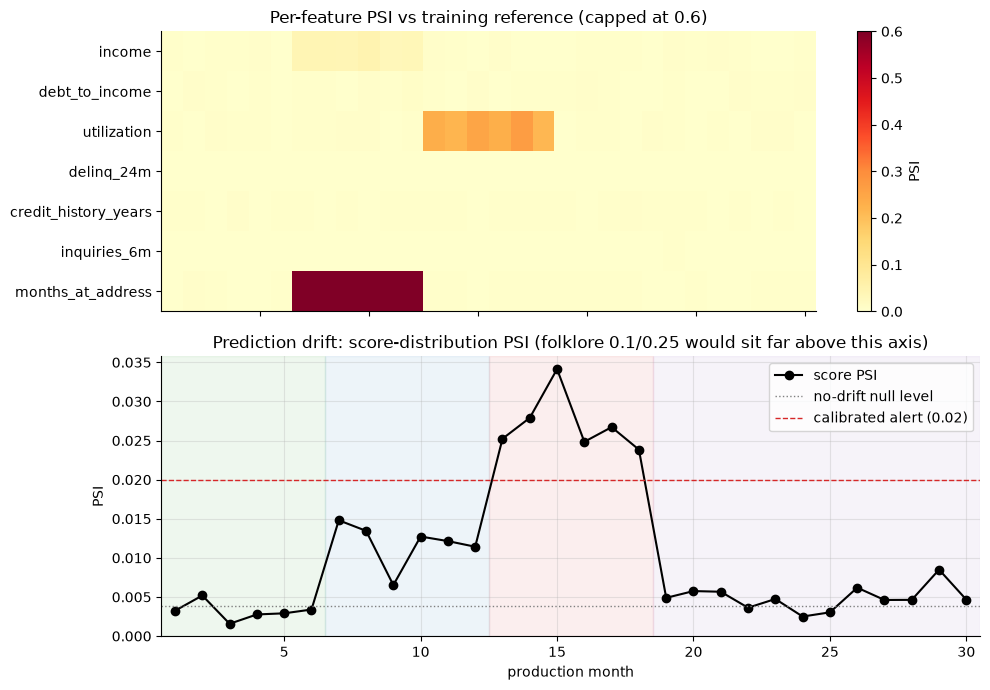

In [7]:
SCORE_PSI_NULL = (B - 1) * (1 / len(test_df) + 1 / N_MONTH)   # no-drift expectation
SCORE_ALERT = 0.02                                            # ~5x null, calibrated
cutoff = np.quantile(ref_scores_0, 0.80)   # approve the 80% least risky at deploy time

monitor_rows = []
for m in range(1, N_MONTHS + 1):
    cur = stream[stream["month"] == m]
    s = model_0.predict_proba(cur[FEATURES])[:, 1]
    row = {
        "month": m,
        "auc_oracle": roc_auc_score(cur["default"], s),   # knowable only in simulation
        "score_psi": psi(ref_scores_0, s),
        "approval_rate": float(np.mean(s < cutoff)),
        "bad_rate": cur["default"].mean(),
        "bad_rate_approved": cur.loc[s < cutoff, "default"].mean(),
    }
    for f in FEATURES:
        row[f"psi_{f}"] = psi(train_df[f], cur[f])
    monitor_rows.append(row)

monitor = pd.DataFrame(monitor_rows).set_index("month")
# what is actually knowable at time t: labels arrive LABEL_DELAY months later
monitor["auc_known"] = monitor["auc_oracle"].shift(LABEL_DELAY)
monitor["bad_rate_known"] = monitor["bad_rate"].shift(LABEL_DELAY)

psi_cols = [f"psi_{f}" for f in FEATURES]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
im = ax1.imshow(monitor[psi_cols].T.values, aspect="auto", cmap="YlOrRd",
                vmin=0, vmax=0.6, extent=[0.5, N_MONTHS + 0.5, len(FEATURES) - 0.5, -0.5])
ax1.set_yticks(range(len(FEATURES)))
ax1.set_yticklabels(FEATURES)
ax1.set_title("Per-feature PSI vs training reference (capped at 0.6)")
ax1.grid(False)
fig.colorbar(im, ax=ax1, label="PSI")

ax2.plot(monitor.index, monitor["score_psi"], "o-", color="black", label="score PSI")
ax2.axhline(SCORE_PSI_NULL, color="gray", ls=":", lw=1, label="no-drift null level")
ax2.axhline(SCORE_ALERT, color="tab:red", ls="--", lw=1,
            label=f"calibrated alert ({SCORE_ALERT})")
shade_regimes(ax2)
ax2.set_xlabel("production month")
ax2.set_ylabel("PSI")
ax2.set_title("Prediction drift: score-distribution PSI "
              "(folklore 0.1/0.25 would sit far above this axis)")
ax2.legend(loc="upper right")
plt.show()

Read the two panels together — this is the whole notebook in one figure:

- **Months 7–12 (campaign):** `months_at_address` burns red (PSI ~3, an order of
  magnitude past every folklore threshold) yet score PSI only creeps to ~3x null — the
  model barely uses what drifted, so the drift barely reaches the predictions.
- **Months 13–18 (bug):** `utilization` shows a *moderate* PSI (~0.23 — a 20% spike at
  zero inside an otherwise unchanged distribution), but score PSI jumps to ~7x its null
  level: the model leans on utilization, so a modest input corruption moves predictions
  hard. Note it still never reaches 0.1 — anyone waiting on folklore thresholds for
  score PSI would sleep through the incident.
- **Months 19–30 (recession):** every panel goes quiet. $P(X)$ is unchanged, so feature
  PSI and score PSI sit exactly at their null level — while (as we'll see) the model is
  at its worst. Input monitoring is structurally blind to concept drift.

### Aside: the domain classifier — multivariate drift detection through a model

Univariate monitors miss joint drift (correlations moving while marginals hold). The
clean general-purpose detector: train a classifier to distinguish *reference rows* from
*production rows*. Held-out AUC ≈ 0.5 means the distributions are indistinguishable;
AUC near 1 means severe drift — and the classifier's important features tell you *where*
it is. Note what it cannot do: month 21 below is deep in the recession, and the domain
classifier shrugs, because concept drift leaves $P(X)$ untouched.

In [8]:
def domain_classifier_auc(ref_df, month_df, seed=0):
    n = min(len(ref_df), len(month_df))
    a = ref_df[FEATURES].sample(n, random_state=seed)
    b = month_df[FEATURES].sample(n, random_state=seed)
    X = pd.concat([a, b], ignore_index=True)
    y = np.r_[np.zeros(n), np.ones(n)]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=seed, stratify=y)
    clf = HistGradientBoostingClassifier(max_iter=60, random_state=seed).fit(Xtr, ytr)
    return roc_auc_score(yte, clf.predict_proba(Xte)[:, 1])


for m in [3, 10, 15, 21]:
    auc_d = domain_classifier_auc(train_df, stream[stream["month"] == m], seed=m)
    print(f"month {m:>2} ({regime_label(m):<18}): domain-classifier AUC = {auc_d:.3f}")

month  3 (01-06 stable      ): domain-classifier AUC = 0.494
month 10 (07-12 benign drift): domain-classifier AUC = 0.857


month 15 (13-18 data bug    ): domain-classifier AUC = 0.629
month 21 (19-30 recession   ): domain-classifier AUC = 0.508


## 3. The delayed-label problem: performance is unmeasurable today

A 90-day default definition means the label for an application booked today **matures**
in ~3 months. Performance metrics are therefore a rear-view mirror with a 3-month blind
spot: the AUC you can compute at month $t$ describes the model as of month $t-3$.

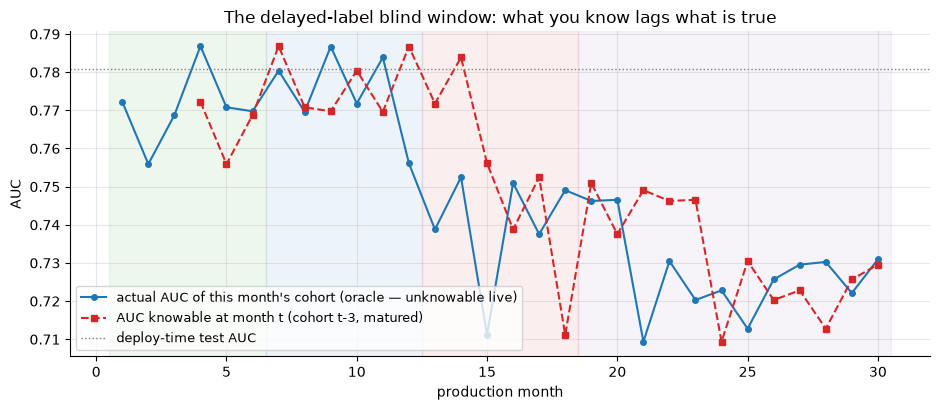

The bug lands in month 13; the first matured-AUC reading that shows it arrives in month 16.
Cohorts 13-15 (9,000 applications) are already booked at the degraded AUC before performance monitoring CAN alert.


In [9]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(monitor.index, monitor["auc_oracle"], "o-", color="tab:blue", ms=4,
        label="actual AUC of this month's cohort (oracle — unknowable live)")
ax.plot(monitor.index, monitor["auc_known"], "s--", color="tab:red", ms=4,
        label=f"AUC knowable at month t (cohort t-{LABEL_DELAY}, matured)")
ax.axhline(auc_test0, color="gray", ls=":", lw=1, label="deploy-time test AUC")
shade_regimes(ax)
ax.set_xlabel("production month")
ax.set_ylabel("AUC")
ax.set_title("The delayed-label blind window: what you know lags what is true")
ax.legend(loc="lower left", fontsize=9)
plt.show()

drop_month = 13
detect_month = drop_month + LABEL_DELAY
print(f"The bug lands in month {drop_month}; the first matured-AUC reading that shows it "
      f"arrives in month {detect_month}.")
print(f"Cohorts {drop_month}-{detect_month - 1} "
      f"({(detect_month - drop_month) * N_MONTH:,} applications) are already booked at the "
      "degraded AUC before performance monitoring CAN alert.")

### What you monitor inside the blind window

Since performance is unmeasurable for 3 months, a senior monitors **proxies, layered by
latency**:

1. **Data quality / schema (instant):** null rates, out-of-range rates, point-mass
   spikes (share of exact zeros!), row counts, feature freshness. Most "drift" pages are
   pipeline bugs, and these checks localize them in minutes with a diagnosable message.
2. **Feature drift (instant):** PSI/KS per feature vs the frozen reference — weighted by
   feature importance, not treated as equally alarming.
3. **Prediction drift (instant):** score-distribution PSI, mean score, score decile mix.
4. **Decision / business KPIs (instant to days):** approval rate, average priced rate,
   queue volumes, manual-review overturn rate. These move when scores move — and the
   business notices them even when ML metrics are green.
5. **Early outcome indicators (weeks):** first-payment default, 30-day delinquency as a
   leading proxy for the 90-day label; a small human-review "canary" sample.
6. **Matured performance (months):** AUC/Gini and calibration by *vintage* (booking
   cohort), the definitive but delayed verdict.

The approval rate deserves special respect: it is label-free, instantaneous, and tied to
money. Watch it catch the bug immediately — bugged applicants look *safer* than they
are, so approvals jump — and stay blind to the recession, where only the lagged bad
rate eventually tells the truth:

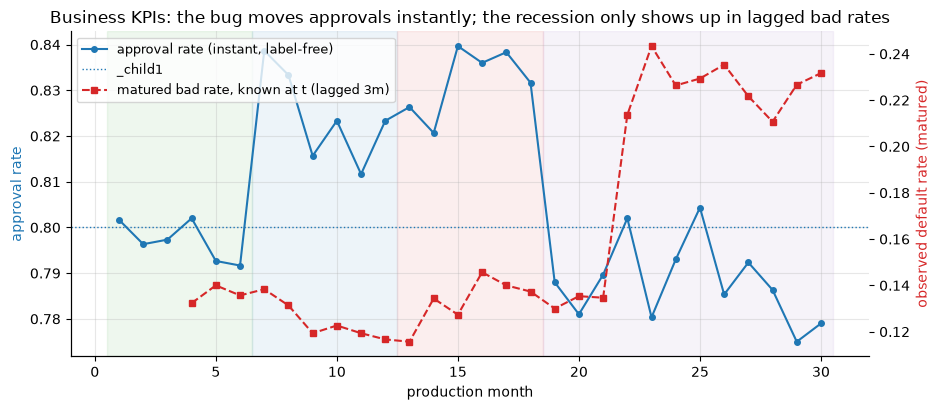

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(monitor.index, monitor["approval_rate"], "o-", color="tab:blue", ms=4,
        label="approval rate (instant, label-free)")
ax.axhline(0.80, color="tab:blue", ls=":", lw=1)
ax.set_ylabel("approval rate", color="tab:blue")
ax.set_xlabel("production month")
ax2 = ax.twinx()
ax2.plot(monitor.index, monitor["bad_rate_known"], "s--", color="tab:red", ms=4,
         label=f"matured bad rate, known at t (lagged {LABEL_DELAY}m)")
ax2.set_ylabel("observed default rate (matured)", color="tab:red")
ax2.grid(False)
shade_regimes(ax)
ax.set_title("Business KPIs: the bug moves approvals instantly; the recession only shows "
             "up in lagged bad rates")
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [ln.get_label() for ln in lines], loc="upper left", fontsize=9)
plt.show()

## 4. The two crucial cases: drift ≠ failure, and small drift can be failure

### Case A — features drift hard, performance holds (benign drift)

The campaign regime shifts `months_at_address` massively — PSI an order of magnitude
beyond every folklore threshold — but the model never learned to use that feature
($P(Y\mid X)$ is unchanged and the feature carries no signal). A drift-alarm-driven team
would have escalated, retrained, maybe rolled back. Nothing was wrong.

In [11]:
base_auc = monitor.loc[1:6, "auc_oracle"].mean()
campaign_auc = monitor.loc[7:12, "auc_oracle"].mean()

case_a = pd.DataFrame({
    "PSI (months 7-12 avg)": monitor.loc[7:12, psi_cols].mean().values,
    "permutation importance": importance.reindex(FEATURES).values,
}, index=FEATURES).sort_values("PSI (months 7-12 avg)", ascending=False)
print(case_a.round(4))
print(f"\nAUC, stable months 1-6   : {base_auc:.3f}")
print(f"AUC, campaign months 7-12: {campaign_auc:.3f}   (delta = {campaign_auc - base_auc:+.4f})")
print("\nScreaming per-feature PSI, zero performance impact: the drifted feature has no "
      "importance.\nA raw-PSI pager would have cried wolf for six months.")

                      PSI (months 7-12 avg)  permutation importance
months_at_address                    2.9061                 -0.0009
income                               0.0391                  0.0560
debt_to_income                       0.0044                  0.0232
utilization                          0.0038                  0.1307
credit_history_years                 0.0026                  0.0181
delinq_24m                           0.0004                  0.0291
inquiries_6m                         0.0002                  0.0035

AUC, stable months 1-6   : 0.771
AUC, campaign months 7-12: 0.775   (delta = +0.0040)

Screaming per-feature PSI, zero performance impact: the drifted feature has no importance.
A raw-PSI pager would have cried wolf for six months.


### Case B — modest drift on a key feature kills AUC

The pipeline bug corrupts `utilization` for only 20% of records. The marginal
distribution barely changes shape — PSI lands around 0.23, an order of magnitude below
the benign alarm above. But utilization is the model's top feature, and for the affected
fifth of applicants the model now reads "zero utilization = very safe" on people whose
true risk is unchanged. We pool the six bug months for stable estimates, and — because
this is a simulation — we can also score the counterfactual where the bug never
happened.

In [12]:
bug_df = stream[stream["month"].between(13, 18)].copy()
s_bug = model_0.predict_proba(bug_df[FEATURES])[:, 1]
bugged = (bug_df["utilization"].eq(0.0) & bug_df["utilization_true"].gt(0)).to_numpy()

bug_clean = bug_df.copy()
bug_clean["utilization"] = bug_clean["utilization_true"]
s_clean = model_0.predict_proba(bug_clean[FEATURES])[:, 1]
y_bug = bug_df["default"].to_numpy()

print(f"utilization PSI, months 13-18 pooled : "
      f"{psi(train_df['utilization'], bug_df['utilization']):.3f}   <- 'moderate'")
print(f"months_at_address PSI, month 10      : "
      f"{monitor.loc[10, 'psi_months_at_address']:.3f}   <- 'major', harmless")
print(f"\nAUC months 13-18, observed (bugged)  : {roc_auc_score(y_bug, s_bug):.3f}")
print(f"AUC months 13-18, counterfactual clean: {roc_auc_score(y_bug, s_clean):.3f}")
print(f"AUC among the 20% bugged records     : {roc_auc_score(y_bug[bugged], s_bug[bugged]):.3f}")
print(f"AUC among unaffected records         : {roc_auc_score(y_bug[~bugged], s_bug[~bugged]):.3f}")

print(f"\nshare of exact zeros in utilization — train: "
      f"{train_df['utilization'].eq(0).mean():.3f}, months 13-18: "
      f"{bug_df['utilization'].eq(0).mean():.3f}")
print("A trivial data-quality check ('share of exact zeros per feature') catches this on "
      "day one\nwith a diagnosable message. PSI needed a month of data and still "
      "whispered 'moderate'.")

utilization PSI, months 13-18 pooled : 0.233   <- 'moderate'
months_at_address PSI, month 10      : 2.724   <- 'major', harmless

AUC months 13-18, observed (bugged)  : 0.740
AUC months 13-18, counterfactual clean: 0.773
AUC among the 20% bugged records     : 0.705
AUC among unaffected records         : 0.768

share of exact zeros in utilization — train: 0.000, months 13-18: 0.201
A trivial data-quality check ('share of exact zeros per feature') catches this on day one
with a diagnosable message. PSI needed a month of data and still whispered 'moderate'.


**The lesson, stated the way you should say it in an interview:** drift magnitude and
performance impact are different axes. Case A is high-drift/zero-impact; Case B is
moderate-drift/high-impact; the recession is zero-drift/high-impact. So:

- **Never page on raw per-feature PSI alone.** Weight drift by what the model does with
  the feature.
- **Estimate expected impact directly**: rescore the drifted batch with each feature
  "de-drifted" (swapped for reference draws) and measure how much the *scores* move.
  That converts "distribution moved" into "predictions moved because of this feature" —
  the quantity an alert should be about. (Same caveat as permutation importance: the
  swap breaks feature correlations.)

In [13]:
def drift_score_impact(model, ref_df, month_df, seed=0):
    """Mean |score change| when each feature is replaced by reference draws."""
    local_rng = np.random.default_rng(seed)
    base = model.predict_proba(month_df[FEATURES])[:, 1]
    out = {}
    for f in FEATURES:
        swapped = month_df[FEATURES].copy()
        swapped[f] = local_rng.choice(ref_df[f].to_numpy(), size=len(month_df))
        out[f] = float(np.mean(np.abs(model.predict_proba(swapped)[:, 1] - base)))
    return pd.Series(out)


impact_tbl = pd.DataFrame({
    "PSI m10 (campaign)": monitor.loc[10, psi_cols].values,
    "score impact m10": drift_score_impact(model_0, train_df, stream[stream["month"] == 10], seed=10),
    "PSI m15 (bug)": monitor.loc[15, psi_cols].values,
    "score impact m15": drift_score_impact(model_0, train_df, stream[stream["month"] == 15], seed=15),
}, index=FEATURES)
print(impact_tbl.round(4))
print("\nRanking by raw PSI puts months_at_address first in both windows. Ranking by "
      "score impact\nputs utilization first in month 15 and ~nothing first in month 10 — "
      "which is the truth.")

                      PSI m10 (campaign)  score impact m10  PSI m15 (bug)  score impact m15
income                            0.0489            0.0584         0.0020            0.0486
debt_to_income                    0.0067            0.0382         0.0059            0.0324
utilization                       0.0051            0.0832         0.2501            0.0879
delinq_24m                        0.0008            0.0357         0.0001            0.0339
credit_history_years              0.0014            0.0315         0.0023            0.0294
inquiries_6m                      0.0004            0.0134         0.0005            0.0140
months_at_address                 2.7245            0.0092         0.0013            0.0074

Ranking by raw PSI puts months_at_address first in both windows. Ranking by score impact
puts utilization first in month 15 and ~nothing first in month 10 — which is the truth.


## 5. Retraining policy: scheduled vs triggered, backtested honestly

Two default policies, both common in industry:

- **Scheduled** (e.g., monthly): simple, predictable, catches slow drift eventually.
  Costs compute and review bandwidth every cycle whether needed or not, and a fixed
  cadence can still be too slow for a shock.
- **Triggered**: retrain when monitoring breaches. Efficient — but the trigger inherits
  every blind spot of the monitor it's built on, and there is a trap almost everyone
  misses in system-design interviews: **the label delay applies to retraining too.**
  When the score-PSI alarm fires at month 13, the freshest *labeled* data is from month
  10 — before the drift. Retraining "immediately" retrains on the old world.

The backtest below enforces that: every retrain may only use cohorts whose labels have
matured (booked ≥ 3 months ago), in a rolling 6-month window. The triggered policy
fires on any of: calibrated score-PSI breach (0.02, from Section 2), matured-AUC
degradation, or matured bad-rate blowout — because no single signal covers all three
drift regimes.

In [14]:
TRAIN_COLS = FEATURES + ["default"]


def matured_training_frame(m, window=6):
    """All data a retrain at month m may legally see: cohorts with matured labels."""
    hi = m - LABEL_DELAY
    if hi < 1:
        return train_df[TRAIN_COLS]
    lo = max(1, hi - window + 1)
    hist = stream.loc[stream["month"].between(lo, hi), TRAIN_COLS]
    if hi - lo + 1 < window:   # not enough production history yet: keep original data too
        return pd.concat([train_df[TRAIN_COLS], hist], ignore_index=True)
    return hist.reset_index(drop=True)


def run_backtest(policy, psi_threshold=SCORE_ALERT, auc_drop=0.04, rate_ratio=1.5,
                 cooldown=2, window=6):
    model = model_0
    ref_scores = ref_scores_0                      # deploy-time held-out reference
    baseline_auc = auc_test0
    baseline_rate = test_df["default"].mean()
    deployed_scores = {}                           # scores as produced at serve time
    last_retrain = -99
    log = []
    for m in range(1, N_MONTHS + 1):
        cur = stream[stream["month"] == m]
        s = model.predict_proba(cur[FEATURES])[:, 1]
        deployed_scores[m] = s
        s_psi = psi(ref_scores, s)

        mat_m = m - LABEL_DELAY                    # newest cohort with matured labels
        mat_auc, mat_rate = np.nan, np.nan
        if mat_m >= 1:
            mc = stream[stream["month"] == mat_m]
            mat_auc = roc_auc_score(mc["default"], deployed_scores[mat_m])
            mat_rate = mc["default"].mean()

        retrain, reasons = False, []
        if policy == "monthly":
            retrain = m >= 4
        elif policy == "triggered":
            if s_psi > psi_threshold:
                reasons.append(f"score PSI {s_psi:.3f}")
            if not np.isnan(mat_auc) and mat_auc < baseline_auc - auc_drop:
                reasons.append(f"matured AUC {mat_auc:.3f}")
            if not np.isnan(mat_rate) and mat_rate > rate_ratio * baseline_rate:
                reasons.append(f"matured bad rate {mat_rate:.2f}")
            retrain = bool(reasons) and (m - last_retrain) > cooldown

        log.append({"month": m,
                    "auc": roc_auc_score(cur["default"], s),   # oracle, for scoring policies
                    "score_psi": s_psi, "matured_auc": mat_auc,
                    "retrained": retrain, "reasons": "; ".join(reasons)})

        if retrain:                                # takes effect from month m+1
            pool = matured_training_frame(m, window)
            hold = pool.sample(frac=0.2, random_state=m)
            fit = pool.drop(hold.index)
            model = HistGradientBoostingClassifier(max_iter=120, random_state=42)
            model.fit(fit[FEATURES], fit["default"])
            ref_scores = model.predict_proba(hold[FEATURES])[:, 1]
            baseline_auc = roc_auc_score(hold["default"], ref_scores)
            baseline_rate = hold["default"].mean()
            last_retrain = m
    return pd.DataFrame(log)


results = {p: run_backtest(p) for p in ["never", "monthly", "triggered"]}

fired = results["triggered"].query("retrained")
print("triggered policy — retrains and why:")
print(fired[["month", "reasons"]].to_string(index=False))

triggered policy — retrains and why:
 month                            reasons
    13                    score PSI 0.025
    16                    score PSI 0.048
    19 score PSI 0.020; matured AUC 0.723
    22              matured bad rate 0.21
    25              matured bad rate 0.23


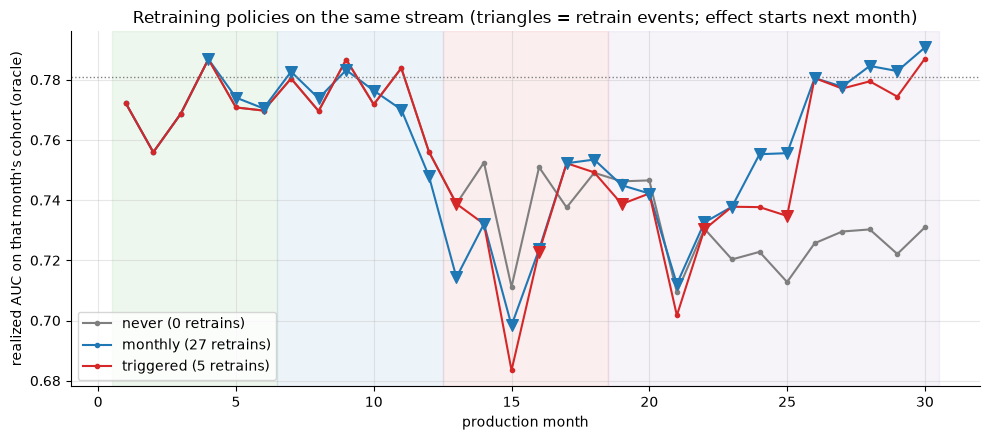

                     never  monthly  triggered
month                                         
01-06 stable        0.7707   0.7714     0.7707
07-12 benign drift  0.7748   0.7724     0.7748
13-18 data bug      0.7400   0.7290     0.7298
19-30 recession     0.7273   0.7581     0.7518
TOTAL retrains      0.0000  27.0000     5.0000


In [15]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = {"never": "tab:gray", "monthly": "tab:blue", "triggered": "tab:red"}
for p, df in results.items():
    ax.plot(df["month"], df["auc"], "-", color=colors[p], marker=".",
            label=f"{p} ({int(df['retrained'].sum())} retrains)")
    rt = df[df["retrained"]]
    ax.scatter(rt["month"], rt["auc"], color=colors[p], marker="v", s=70, zorder=5)
ax.axhline(auc_test0, color="gray", ls=":", lw=1)
shade_regimes(ax)
ax.set_xlabel("production month")
ax.set_ylabel("realized AUC on that month's cohort (oracle)")
ax.set_title("Retraining policies on the same stream (triangles = retrain events; "
             "effect starts next month)")
ax.legend(loc="lower left")
plt.show()

summary = pd.DataFrame({p: df.groupby(df["month"].map(regime_label))["auc"].mean()
                        for p, df in results.items()})
summary.loc["TOTAL retrains"] = [results[p]["retrained"].sum() for p in summary.columns]
print(summary.round(4))

### Reading the backtest like a senior

- **Stable + benign months:** the three policies are indistinguishable. Every monthly
  retrain in months 4–12 was pure cost — nothing had changed that the model cared about.
- **The bug regime shows retraining can even hurt.** The trigger fires at month 13, but
  that retrain sees only *pre-bug* matured cohorts — it reproduces the old model and
  changes nothing. Later retrains adapt only partially (they merely learn that
  "utilization = 0" is ambiguous) while giving up the original large clean training
  set, and both retraining policies finish the regime slightly *below* the frozen
  model. None comes near the counterfactual clean AUC from Case B: the destroyed
  information is not recoverable by any amount of retraining. The correct action was
  never retraining; it was **fixing the pipeline**, which the zero-share data-quality
  check localized on day one.
- **The recession is where retraining genuinely pays.** $P(Y\mid X)$ itself moved, the
  new world is learnable, and it persists — so policies that retrain on matured
  recession cohorts climb well above the frozen model. But notice the mechanics: the
  PSI trigger contributed nothing here (no input drift); the matured bad-rate and AUC
  triggers did the work, months late by necessity. Label delay caps how fast *any*
  retraining policy can adapt to concept drift.
- **Triggered ≈ monthly on realized AUC at a fraction of the retrains.** The value of a
  good trigger is mostly cost, stability, and review bandwidth — in regulated settings
  every retrain is a validation event, so fewer, better-justified retrains win.
- Production wisdom this backtest encodes: retrain on a *schedule as backstop*, add
  *performance/calibration triggers* (not just input-drift triggers), and always promote
  via champion/challenger comparison on matured cohorts rather than blind swap.

## 6. What a senior puts on the dashboard

One page, layered by latency, each layer answering a different question:

| Layer | Signals | Latency | Question answered |
|---|---|---|---|
| Data quality / schema | null %, exact-zero %, out-of-range %, cardinality, row count, freshness | minutes | "Is the pipeline broken?" |
| Feature drift | PSI/KS vs frozen reference, importance-weighted; domain-classifier AUC | hours | "Has the population moved, and where?" |
| Prediction drift | score PSI, mean score, decile mix | hours | "Have decisions moved?" |
| Decisions / business | approval rate, queue volume, review overturn %, unit economics | hours–days | "Is money moving?" |
| Delayed performance | AUC/Gini and calibration **by vintage**, early-indicator labels | weeks–months | "Was the model actually right?" |

Alerting rules of the senior variety: page on data-quality failures and on
*impact-weighted* drift; ticket (don't page) raw feature drift; every alert carries a
runbook ("check the upstream release calendar" comes before "consider retraining");
thresholds calibrated on your own null, per segment; and every alarm gets resolved as
bug / benign / harmful so the thresholds can learn. Alert fatigue — pages that are
usually false — is how monitoring dies in practice.

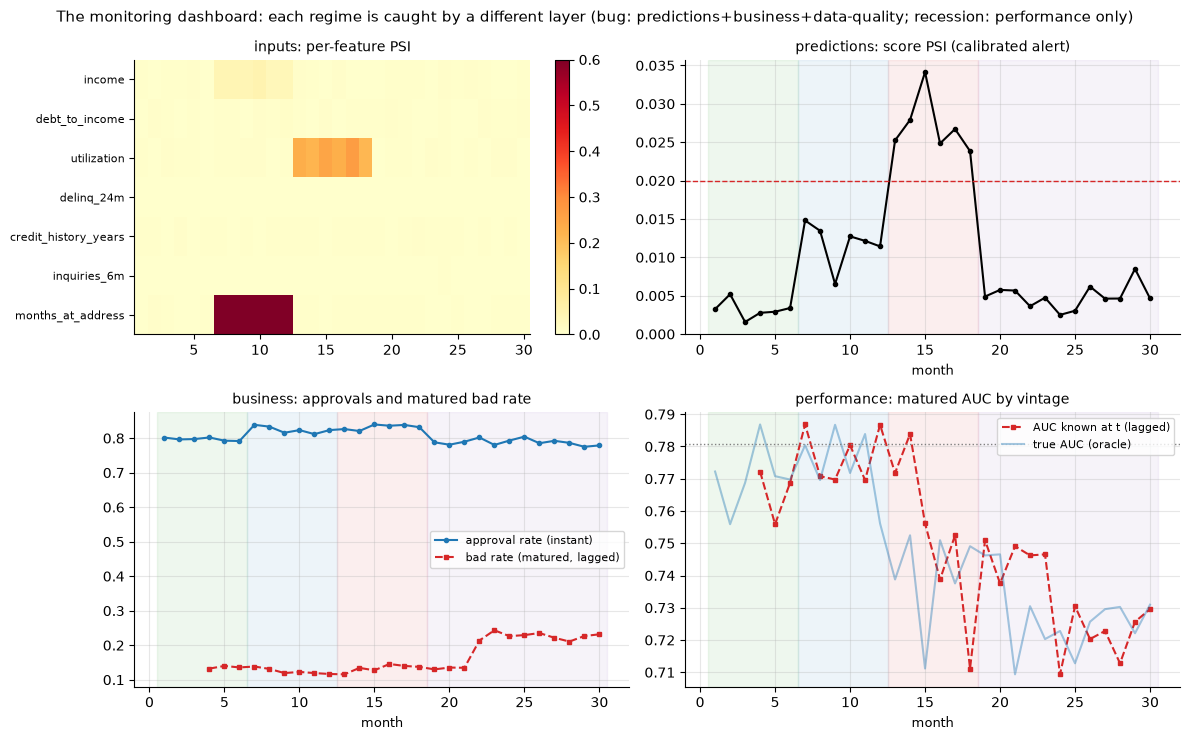

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

axm = axes[0, 0]
im = axm.imshow(monitor[psi_cols].T.values, aspect="auto", cmap="YlOrRd",
                vmin=0, vmax=0.6, extent=[0.5, N_MONTHS + 0.5, len(FEATURES) - 0.5, -0.5])
axm.set_yticks(range(len(FEATURES)))
axm.set_yticklabels(FEATURES, fontsize=8)
axm.set_title("inputs: per-feature PSI", fontsize=10)
axm.grid(False)
fig.colorbar(im, ax=axm)

axs = axes[0, 1]
axs.plot(monitor.index, monitor["score_psi"], "o-", color="black", ms=3)
axs.axhline(SCORE_ALERT, color="tab:red", ls="--", lw=1)
shade_regimes(axs)
axs.set_title("predictions: score PSI (calibrated alert)", fontsize=10)

axb = axes[1, 0]
axb.plot(monitor.index, monitor["approval_rate"], "o-", color="tab:blue", ms=3,
         label="approval rate (instant)")
axb.plot(monitor.index, monitor["bad_rate_known"], "s--", color="tab:red", ms=3,
         label="bad rate (matured, lagged)")
shade_regimes(axb)
axb.set_title("business: approvals and matured bad rate", fontsize=10)
axb.legend(fontsize=8)

axa = axes[1, 1]
axa.plot(monitor.index, monitor["auc_known"], "s--", color="tab:red", ms=3,
         label="AUC known at t (lagged)")
axa.plot(monitor.index, monitor["auc_oracle"], "-", color="tab:blue", alpha=0.4,
         label="true AUC (oracle)")
axa.axhline(auc_test0, color="gray", ls=":", lw=1)
shade_regimes(axa)
axa.set_title("performance: matured AUC by vintage", fontsize=10)
axa.legend(fontsize=8)

for ax_ in [axs, axb, axa]:
    ax_.set_xlabel("month", fontsize=9)
fig.suptitle("The monitoring dashboard: each regime is caught by a different layer "
             "(bug: predictions+business+data-quality; recession: performance only)",
             fontsize=11)
plt.show()

## 7. Pitfalls

1. **Fixed PSI thresholds regardless of sample size** — the null level of PSI scales
   like $(B-1)(1/n+1/m)$; the 0.1 rule fires on noise for small slices and is numb at
   scale, and folklore thresholds never fire on tight score distributions (Section 2).
2. **KS p-values as drift alarms at production n** — everything is "significant"; watch
   the statistic, not the p-value (Section 2).
3. **Raw drift alarms treated as model failure** — Case A vs Case B (Section 4); alert
   on expected impact.
4. **The boiling frog: comparing against a rolling reference.** Month-over-month
   comparisons never alarm on slow drift — each step is tiny while the cumulative shift
   is huge. Compare against a *frozen* reference (and update it deliberately, at
   revalidation).
5. **Evaluating (or retraining) on immature labels.** Early-arriving labels are not a
   random sample of eventual labels — the fastest defaults are the most extreme cases,
   so early reads are biased, usually flattering.

Pitfalls 4 and 5 demonstrated below.

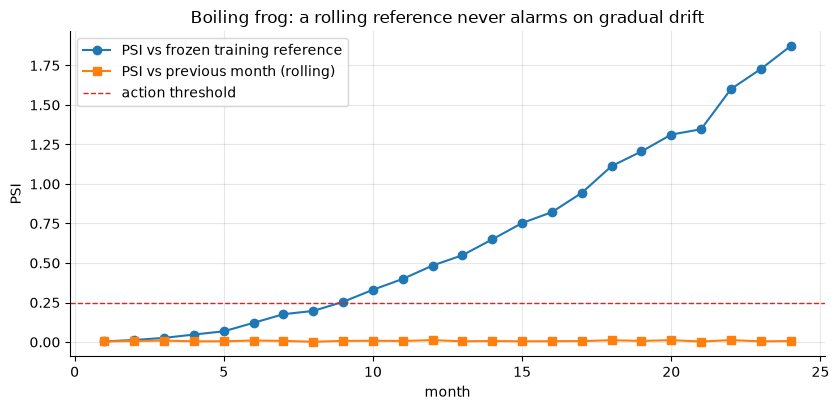

cumulative shift after 24 months: 1.44 sd — frozen-reference PSI 1.87, rolling PSI 0.006


In [17]:
# Pitfall 4: the boiling frog — slow drift, rolling vs frozen reference
n_bf, n_months_bf = 5_000, 24
drift_per_month = 0.06                        # +0.06 sd per month => 1.44 sd total
batches = [rng.normal(loc=drift_per_month * t, scale=1.0, size=n_bf)
           for t in range(n_months_bf + 1)]

psi_frozen = [psi(batches[0], batches[t]) for t in range(1, n_months_bf + 1)]
psi_rolling = [psi(batches[t - 1], batches[t]) for t in range(1, n_months_bf + 1)]

fig, ax = plt.subplots()
ax.plot(range(1, n_months_bf + 1), psi_frozen, "o-", label="PSI vs frozen training reference")
ax.plot(range(1, n_months_bf + 1), psi_rolling, "s-", label="PSI vs previous month (rolling)")
ax.axhline(0.25, color="tab:red", ls="--", lw=1, label="action threshold")
ax.set_xlabel("month")
ax.set_ylabel("PSI")
ax.set_title("Boiling frog: a rolling reference never alarms on gradual drift")
ax.legend()
plt.show()
print(f"cumulative shift after 24 months: {drift_per_month * 24:.2f} sd — "
      f"frozen-reference PSI {psi_frozen[-1]:.2f}, rolling PSI {psi_rolling[-1]:.3f}")

In [18]:
# Pitfall 5: immature labels — early defaulters are the riskiest, so early reads flatter
cohort = gen_applications(20_000, rng)
scores_c = model_0.predict_proba(cohort[FEATURES])[:, 1]

# defaulters' event times: riskier applicants default sooner (realistic and crucial)
is_def = cohort["default"].eq(1).to_numpy()
event_days = np.full(len(cohort), np.inf)
event_days[is_def] = (rng.exponential(60.0, is_def.sum())
                      * (0.12 / cohort.loc[is_def, "p_true"].to_numpy()) ** 0.7)

rows = []
for day in [30, 60, 90, 180]:
    label_now = (event_days <= day).astype(int)     # what you'd observe at this snapshot
    rows.append({"snapshot day": day,
                 "observed bad rate": label_now.mean(),
                 "AUC vs snapshot labels": roc_auc_score(label_now, scores_c)})
snap = pd.DataFrame(rows).set_index("snapshot day")
snap.loc["mature (truth)"] = [cohort["default"].mean(),
                              roc_auc_score(cohort["default"], scores_c)]
print(snap.round(4))
print("\nAt day 30 the observed bad rate is a small fraction of the true rate, and the "
      "AUC is\ninflated: the only visible defaulters are the extreme ones the model finds "
      "easy.\n'The new model looks great so far' is exactly this artifact.")

                observed bad rate  AUC vs snapshot labels
snapshot day                                             
30                         0.0716                  0.8425
60                         0.1031                  0.8264
90                         0.1168                  0.8177
180                        0.1310                  0.7931
mature (truth)             0.1387                  0.7689

At day 30 the observed bad rate is a small fraction of the true rate, and the AUC is
inflated: the only visible defaulters are the extreme ones the model finds easy.
'The new model looks great so far' is exactly this artifact.


## 8. Interview corner

**Q1. "Your model has been in production for a year. How do you know it's still good?"**
Layered answer, ordered by latency: (1) data-quality/schema checks — most incidents are
pipeline bugs, catch them in minutes; (2) feature drift vs a frozen reference,
importance-weighted; (3) prediction drift — score-distribution PSI, the single best
label-free summary; (4) decision/business KPIs (approval rate, queue volume); (5) matured
performance and calibration *by vintage* once labels arrive. Emphasize the distinction:
drift detection is immediate but impact-blind; performance evaluation is definitive but
delayed. Bonus points: champion/challenger kept warm, and every alert tied to expected
impact, not raw distribution distance.

**Q2. "Explain PSI. What are its limitations?"**
Mechanics: bin the reference (deciles, edges frozen at deploy), compare bin shares,
$\sum (a_i-e_i)\ln(a_i/e_i)$ — symmetrized KL on binned data. Conventions: <0.1 stable,
0.1–0.25 watch, >0.25 act. Limits a senior must volunteer: the thresholds are folklore —
the null expectation is $\approx (B-1)(1/n+1/m)$, so their meaning depends on sample
size and bin count, and they don't transfer at all to tight distributions like model
scores; PSI is univariate (misses joint drift); it is impact-blind (Case A vs Case B);
binning choices change the number; discrete features need edge handling. Fix: calibrate
thresholds on your own null by resampling, weight by importance, monitor scores too.

**Q3. "Labels take 3 months to arrive. What do you monitor starting tomorrow?"**
Everything label-free, layered: schema/data-quality, per-feature drift, score
distribution, decision KPIs. Then build outcome contact earlier than 90 days:
early-delinquency indicators (first-payment default, 30-day past-due) as leading labels,
a small manual-review canary sample. Set up vintage-based performance dashboards that
fill in as cohorts mature — and name the immature-label bias: early defaults are the
extreme ones, so partial-label AUC and bad rates are biased (usually flattering).

**Q4. "A feature's PSI breached 0.25. Do you retrain?"**
No — triage first. (1) Data quality: null/zero-rate spike, schema change, upstream
release calendar — most breaches are bugs, and retraining on a bug bakes it in. (2)
Impact: does the model use this feature (importance)? Did the *score* distribution move?
Estimate expected impact by de-drifted rescoring. (3) Segment: is it one channel or
geography? Only if it's a genuine population shift with expected impact do you consider
retraining — and remember the label delay means fresh labels describing the new world
may not exist yet.

**Q5. "Scheduled vs triggered retraining — how would you decide?"**
Scheduled: predictable ops, catches slow drift, wasteful when stable, cadence may be too
slow for shocks. Triggered: efficient, but inherits the monitor's blind spots (input
triggers never see concept drift) and the label delay means retrain-on-breach often
trains on pre-drift data. Strong answer: both — a scheduled backstop plus
performance/calibration triggers, every promotion gated by champion/challenger on
matured cohorts, and an explicit note that retraining doesn't fix data bugs or beat the
label-delay information limit.

**Q6. "How do you detect concept drift if the feature distributions are stable?"**
By definition you cannot from $X$ alone — feature PSI, score PSI, and a domain
classifier all read green. You need outcome contact: matured vintage AUC and calibration
(predicted vs realized by cohort), early-indicator labels, sampled human review, and
external leading covariates (macro indicators for credit, attack intel for fraud).
Showing you know monitoring has a structural blind spot — and that you design labeled
feedback paths on purpose — is the senior signal.

**Q7. "Prediction drift fired but business KPIs look fine. Now what?"**
Quantify decision impact first: did scores cross action thresholds, or just move within
bands? Check for expected causes (seasonality, mix shift, upstream product change) and
whether the KPI is simply lagged or insensitive. If genuine but impact-free: document
and adjust the alert, don't retrain — protecting alert credibility is part of the job.

## Key takeaways

- Decompose rot precisely: covariate drift = $P(X)$, concept drift = $P(Y\mid X)$, label
  shift = $P(Y)$. Detectability and harm are *different axes*: covariate drift is visible
  but often benign; concept drift is invisible from inputs but always matters.
- PSI = $\sum (a_i-e_i)\ln(a_i/e_i)$ on reference-quantile bins with frozen edges. The
  0.1/0.25 thresholds are folklore: the null level scales as $(B-1)(1/n+1/m)$ — calibrate
  thresholds on your own null, and expect score PSI to live on a much smaller scale than
  raw-feature PSI.
- At production sample sizes KS p-values are always significant; monitor effect sizes.
- Score-distribution PSI is the best single label-free monitor — it weights feature
  drift by what the model does with it — but it is blind to concept drift.
- Delayed labels split monitoring into detection (instant, impact-blind) and evaluation
  (definitive, lagged). Fill the blind window with data-quality checks, score/decision
  KPIs, and early-indicator labels; report performance by vintage.
- Drift alarms are not model failure: huge PSI on an unimportant feature costs nothing;
  a "moderate" PSI on the top feature can cost several AUC points. Alert on expected
  impact (importance-weighted drift, de-drifted rescoring), never raw distance.
- Most "drift" is a pipeline bug. Zero/null-rate checks catch it in minutes with a
  diagnosable message; retraining on a bug bakes it in and cannot recover the destroyed
  information.
- Retraining is not a time machine: label delay means retrain-on-breach often retrains
  on the pre-drift world, and adaptation to concept drift starts only when post-shift
  cohorts mature. Use a scheduled backstop + performance triggers + champion/challenger
  promotion.

## Exercises

**Exercise 1.** Implement PSI with *equal-width* bins and compare it to the quantile
version on `income` (heavily right-skewed): (a) under no drift, (b) under a real 15%
income shift. Explain why equal-width binning is close to blind here.

**Exercise 2.** Backtest the *pure* score-PSI trigger (no performance or bad-rate
conditions) at thresholds 0.25 (folklore), 0.05, and 0.02 (our calibrated alert).
Report retrains and mean realized AUC over months 13–30. Which regimes does each
threshold catch, which does no threshold catch, and why?

**Exercise 3.** Label-shift correction: by month 23 you know (from matured cohorts
19–20) that the base rate jumped. Apply the prior-shift correction to the frozen
model's scores for months 25–30,
$\mathrm{logit}(s') = \mathrm{logit}(s) + \ln\frac{\pi_{new}/(1-\pi_{new})}{\pi_{ref}/(1-\pi_{ref})}$,
and compare predicted vs realized default rates and AUC before/after. What does the
correction fix, what can't it fix, and which assumption does it lean on?

In [19]:
# --- Solution 1 ---
def psi_equal_width(reference, actual, n_bins=10, eps=1e-4):
    reference, actual = np.asarray(reference), np.asarray(actual)
    edges = np.linspace(reference.min(), reference.max(), n_bins + 1)[1:-1]
    ref_frac = np.bincount(np.searchsorted(edges, reference, side="right"),
                           minlength=n_bins) / len(reference)
    act_frac = np.bincount(np.searchsorted(edges, actual, side="right"),
                           minlength=n_bins) / len(actual)
    ref_frac, act_frac = np.clip(ref_frac, eps, None), np.clip(act_frac, eps, None)
    return float(np.sum((act_frac - ref_frac) * np.log(act_frac / ref_frac)))


ref_inc = train_df["income"].to_numpy()
same = rng.lognormal(np.log(55.0), 0.5, 5_000)            # no drift
shifted = rng.lognormal(np.log(55.0 * 1.15), 0.5, 5_000)  # +15% income

ex1 = pd.DataFrame({
    "quantile bins": [psi(ref_inc, same), psi(ref_inc, shifted)],
    "equal-width bins": [psi_equal_width(ref_inc, same), psi_equal_width(ref_inc, shifted)],
}, index=["no drift", "+15% income shift"])
print(ex1.round(4))
print(f"\nreference income: median {np.median(ref_inc):.0f}k, max {ref_inc.max():.0f}k")
print("Equal-width bins span [min, max] of a long-tailed feature, so nearly all mass "
      "falls in\nthe first few bins; a 15% shift moves people *within* those wide bins "
      "and barely\nregisters. Quantile bins hold equal reference mass, so the same shift "
      "is unmissable.\n(Equal-width edges also depend on the sample max — one outlier "
      "reshapes every bin.)")

                   quantile bins  equal-width bins
no drift                  0.0030            0.0015
+15% income shift         0.0854            0.0716

reference income: median 55k, max 479k
Equal-width bins span [min, max] of a long-tailed feature, so nearly all mass falls in
the first few bins; a 15% shift moves people *within* those wide bins and barely
registers. Quantile bins hold equal reference mass, so the same shift is unmissable.
(Equal-width edges also depend on the sample max — one outlier reshapes every bin.)


In [20]:
# --- Solution 2 ---
rows = []
for thr in [0.25, 0.05, 0.02]:
    bt = run_backtest("triggered", psi_threshold=thr,
                      auc_drop=np.inf, rate_ratio=np.inf)   # PSI-only trigger
    rows.append({"psi threshold": thr,
                 "retrains": int(bt["retrained"].sum()),
                 "fired months": ", ".join(map(str, bt.loc[bt["retrained"], "month"])),
                 "mean AUC m13-30": bt.loc[bt["month"] >= 13, "auc"].mean()})
never_auc = results["never"].loc[results["never"]["month"] >= 13, "auc"].mean()
full_auc = results["triggered"].loc[results["triggered"]["month"] >= 13, "auc"].mean()
ex2 = pd.DataFrame(rows).set_index("psi threshold")
print(ex2.round(4))
print(f"(never retrain, same window        : {never_auc:.4f})")
print(f"(full trigger incl. matured perf.  : {full_auc:.4f})")
print("\nThe folklore thresholds (0.25, even 0.05) never fire at all: score PSI peaks "
      "near 0.03\nbecause score distributions are tight — folklore numbers were "
      "calibrated on raw\nscorecard features. Only the null-calibrated 0.02 alert reacts "
      "to the bug — and its\nretrains actually LOWER realized AUC: the first trains on "
      "pre-bug matured labels\n(no change), the later ones trade the large clean training "
      "set for small,\npartly-bugged windows just as the bug ends. Meanwhile no PSI-only "
      "trigger EVER fires\nfor the recession — the one shift where retraining pays — "
      "because score PSI is a\nfunction of X and the recession leaves X unchanged. That "
      "is why the main backtest\nadded matured-AUC and bad-rate conditions, and why its "
      "mean AUC is far higher.")

               retrains fired months  mean AUC m13-30
psi threshold                                        
0.25                  0                        0.7315
0.05                  0                        0.7315
0.02                  3   13, 16, 19           0.7254
(never retrain, same window        : 0.7315)
(full trigger incl. matured perf.  : 0.7445)

The folklore thresholds (0.25, even 0.05) never fire at all: score PSI peaks near 0.03
because score distributions are tight — folklore numbers were calibrated on raw
scorecard features. Only the null-calibrated 0.02 alert reacts to the bug — and its
retrains actually LOWER realized AUC: the first trains on pre-bug matured labels
(no change), the later ones trade the large clean training set for small,
partly-bugged windows just as the bug ends. Meanwhile no PSI-only trigger EVER fires
for the recession — the one shift where retraining pays — because score PSI is a
function of X and the recession leaves X unchanged. That is why the

In [21]:
# --- Solution 3 ---
pi_ref = train_df["default"].mean()
# knowable at month 23: matured recession cohorts 19-20
pi_new = stream.loc[stream["month"].isin([19, 20]), "default"].mean()
shift = logit(pi_new) - logit(pi_ref)

late = stream[stream["month"] >= 25]
s_raw = np.clip(model_0.predict_proba(late[FEATURES])[:, 1], 1e-6, 1 - 1e-6)
s_adj = expit(logit(s_raw) + shift)

print(f"reference base rate: {pi_ref:.3f}   matured recession base rate: {pi_new:.3f}")
print(f"\nmonths 25-30 realized default rate : {late['default'].mean():.3f}")
print(f"mean predicted, raw scores         : {s_raw.mean():.3f}   <- badly under-predicts")
print(f"mean predicted, prior-corrected    : {s_adj.mean():.3f}")
print(f"\nAUC raw vs corrected: {roc_auc_score(late['default'], s_raw):.4f} vs "
      f"{roc_auc_score(late['default'], s_adj):.4f}  (identical — monotone transform)")
print("\nThe correction fixes the calibration LEVEL (expected-loss pricing, expected "
      "approval\nbad rates) using only a matured base rate — cheap and fast. It cannot "
      "fix ranking:\nthe recession also reweighted P(Y|X) (delinquencies and DTI matter "
      "more, income\nless), which only retraining on matured recession data can learn — "
      "exactly what the\nbacktest's retrained policies did. And it leans on the pure "
      "label-shift assumption\nP(X|Y) unchanged — here only approximately true, so "
      "residual miscalibration remains.")

reference base rate: 0.132   matured recession base rate: 0.229

months 25-30 realized default rate : 0.223
mean predicted, raw scores         : 0.135   <- badly under-predicts
mean predicted, prior-corrected    : 0.213

AUC raw vs corrected: 0.7254 vs 0.7254  (identical — monotone transform)

The correction fixes the calibration LEVEL (expected-loss pricing, expected approval
bad rates) using only a matured base rate — cheap and fast. It cannot fix ranking:
the recession also reweighted P(Y|X) (delinquencies and DTI matter more, income
less), which only retraining on matured recession data can learn — exactly what the
backtest's retrained policies did. And it leans on the pure label-shift assumption
P(X|Y) unchanged — here only approximately true, so residual miscalibration remains.
